# Guided Score Surface — Squares in Squares
_The grid charge for packing n unit squares, n = 1 through 1000_

***

**Programming Language:** Python in the Jupyter Notebook Environment

**Competition:** [squares-in-squares](https://www.kaggle.com/competitions/squares-in-squares/data)

**Style counterpart:** [Guided Numeric and Text Exploration — E-Commerce](https://www.kaggle.com/code/nicapotato/guided-numeric-and-text-exploration-e-commerce)

**Code Navigation:** <br>
In the code, text after hashtags (`#`) are supportive explanations, not executed as code.

***

# Tables of Content:

**1. [Introduction](#Introduction)** <br>
**2. [Setup](#Setup)** <br>
**3. [The Grid Charge](#Grid)** <br>
**4. [Where the Charge Spikes](#Spikes)** <br>
**5. [A Straight Line Through the Sawtooth](#Model)** <br>
**6. [What It Means — Working Synthesis](#Synthesis)** <br>

# **1. Introduction:** <a id="Introduction"></a> <br>
Squares in Squares asks for a packing of n unit squares into a larger square, for every n from 1 through 1000. A submission row names the puzzle, the small square, and that square's position and angle. The competition page publishes no input table. A missing or rejected puzzle is charged the axis-aligned grid: side L = ceil(sqrt(n)), and the puzzle score is L / sqrt(n) − 1. The entry score is the sum of those puzzle scores. Lower is better.

This notebook builds that grid for every n, scores it, and reads the surface. Perfect squares land on score 0, because n unit squares fill a sqrt(n) by sqrt(n) grid. Every other n pays for the empty cells in the next larger grid. The sum of the grid charge from n = 1 through 1000 is 28.9377.

# **2. Setup:** <a id="Setup"></a>

In [1]:
# General
import numpy as np
import pandas as pd
from pathlib import Path

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Scientific / modeling helpers
from IPython.display import display
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

import kagglehub

# Set Plot Theme (same family as the guided series)
sns.set_theme(style="whitegrid")
PALETTE = ["#30a2da", "#fc4f30", "#e5ae38", "#6d904f", "#8b8b8b"]
sns.set_palette(PALETTE)
plt.rcParams["figure.figsize"] = (11, 5)

# Warnings
import warnings
warnings.filterwarnings("ignore")

# Wide table inspection in Jupyter cell outputs
pd.set_option("display.max_columns", 999)
pd.set_option("display.width", 220)


def park_legend(ax, title=""):
    ax.legend(
        title=title,
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        borderaxespad=0,
        frameon=False,
    )

/Users/nicapotato/Documents/repo/project/KaggleNotebooks/eda/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


**Code Explanation and Reasoning:** <br>
The same plotting and modeling stack as the rest of the guided series. `kagglehub` is imported with that stack. This competition publishes no file to download, so the notebook builds the grid in memory. `park_legend` keeps any legend to the right of the axes.

In [2]:
kaggle_root = Path("/kaggle/input")
if kaggle_root.exists():
    found = [p for p in kaggle_root.rglob("*") if p.is_file()]
    print("Files under /kaggle/input:", len(found))
else:
    print("No /kaggle/input directory in this session.")
print("Squares in Squares publishes no input table.")
print("The grid below is the charge for a missing puzzle: L = ceil(sqrt(n)).")

ns = np.arange(1, 1001)
side = np.ceil(np.sqrt(ns))
score = side / np.sqrt(ns) - 1
grid = pd.DataFrame({"n": ns, "side": side.astype(int), "score": score})
perfect = grid.loc[np.isclose(grid.score, 0)].copy()
assert len(grid) == 1000
assert len(perfect) == 31
assert int(perfect.n.iloc[0]) == 1 and int(perfect.n.iloc[-1]) == 961
assert int(grid.loc[grid.score.idxmax(), "n"]) == 2
assert np.isclose(grid.score.sum(), 28.93766991655059)
print("Puzzles:", len(grid))
print("Perfect squares, score 0:", len(perfect))
print("Worst n:", int(grid.loc[grid.score.idxmax(), "n"]), "score", round(grid.score.max(), 4))
print("Sum of grid scores, n=1..1000:", round(grid.score.sum(), 4))
display(grid.head(8))

No /kaggle/input directory in this session.
Squares in Squares publishes no input table.
The grid below is the charge for a missing puzzle: L = ceil(sqrt(n)).
Puzzles: 1000
Perfect squares, score 0: 31
Worst n: 2 score 0.4142
Sum of grid scores, n=1..1000: 28.9377


,n,side,score
0,1,1,0.000000
1,2,2,0.414214
2,3,2,0.154701
3,4,2,0.000000
4,5,3,0.341641
5,6,3,0.224745
6,7,3,0.133893
7,8,3,0.060660


**Interpretation:** <br>
There are 31 perfect squares from 1² through 31² (961). 32² is 1024, past the last puzzle. Each of those 31 puzzles has grid score 0. The worst single puzzle is n = 2: two unit squares need a side of 2, and 2 / sqrt(2) − 1 = 0.4142. The sum of every puzzle's grid charge is 28.9377.

# **3. The Grid Charge:** <a id="Grid"></a>

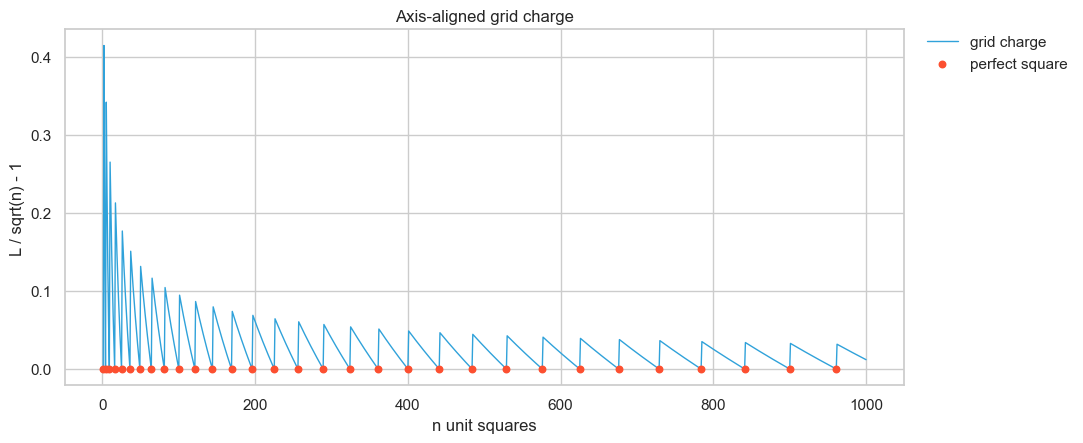

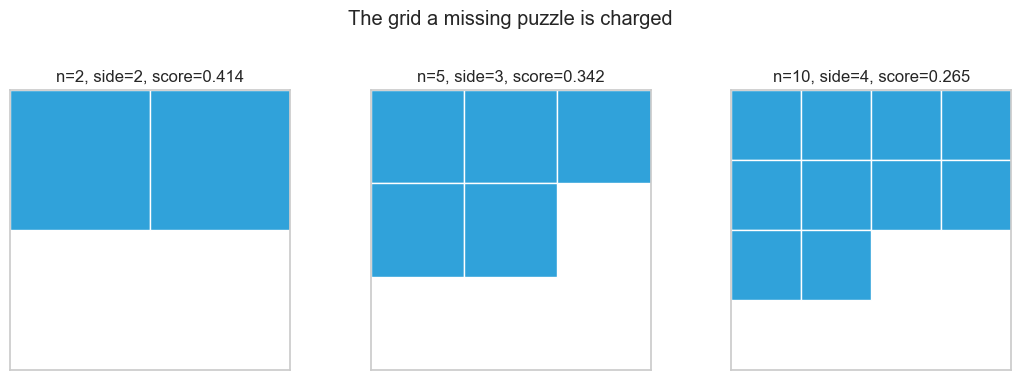

In [3]:
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.plot(grid.n, grid.score, color=PALETTE[0], lw=1, label="grid charge")
ax.scatter(perfect.n, perfect.score, color=PALETTE[1], s=22, zorder=3, label="perfect square")
park_legend(ax)
ax.set_xlabel("n unit squares")
ax.set_ylabel("L / sqrt(n) - 1")
ax.set_title("Axis-aligned grid charge")
fig.tight_layout()
plt.show()


def draw_grid(ax, n):
    from matplotlib.patches import Rectangle
    k = int(np.ceil(np.sqrt(n)))
    for i in range(n):
        row, col = divmod(i, k)
        ax.add_patch(
            Rectangle(
                (col, k - 1 - row),
                1,
                1,
                facecolor=PALETTE[0],
                edgecolor="white",
                linewidth=1,
            )
        )
    ax.set_xlim(0, k)
    ax.set_ylim(0, k)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f"n={n}, side={k}, score={k / np.sqrt(n) - 1:.3f}")


fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for ax, n in zip(axes, [2, 5, 10]):
    draw_grid(ax, n)
fig.suptitle("The grid a missing puzzle is charged", y=1.05)
fig.tight_layout()
plt.show()

**Interpretation:** <br>
The score is a sawtooth. It falls toward 0 as n approaches the next perfect square, hits 0 on that square, and jumps when n crosses into a larger grid. n = 2, n = 5, and n = 10 are the first three jumps: sides 2, 3, and 4, with empty cells still inside the grid. Those empty cells are what the score is charging.

# **4. Where the Charge Spikes:** <a id="Spikes"></a>

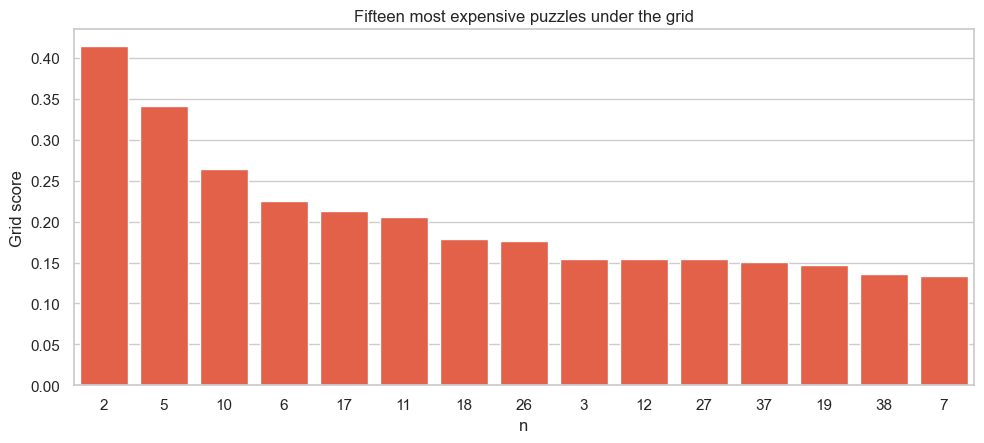

,n,side,score,n_label
1,2,2,0.4142,2
4,5,3,0.3416,5
9,10,4,0.2649,10
5,6,3,0.2247,6
16,17,5,0.2127,17
10,11,4,0.2060,11
17,18,5,0.1785,18
25,26,6,0.1767,26
2,3,2,0.1547,3
11,12,4,0.1547,12


Score on the puzzle just after each perfect square:


,n,previous_square,side,score
0,2,1,2,0.4142
1,5,4,3,0.3416
2,10,9,4,0.2649
3,17,16,5,0.2127
4,26,25,6,0.1767
5,37,36,7,0.1508
6,50,49,8,0.1314
7,65,64,9,0.1163


Largest just-after jump: 2 0.4142
Smallest just-after jump: 962 0.0317


In [4]:
worst = grid.nlargest(15, "score").copy()
worst["n_label"] = worst.n.astype(int).astype(str)
fig, ax = plt.subplots(figsize=(10, 4.6))
sns.barplot(data=worst, x="n_label", y="score", order=worst.n_label.tolist(), ax=ax, color=PALETTE[1])
ax.set_xlabel("n")
ax.set_ylabel("Grid score")
ax.set_title("Fifteen most expensive puzzles under the grid")
fig.tight_layout()
plt.show()
display(worst.assign(score=worst.score.round(4)))

just_after = []
for k in range(1, 32):
    n = k * k + 1
    if n > 1000:
        break
    row = grid.loc[grid.n.eq(n)].iloc[0]
    just_after.append({"n": int(n), "previous_square": k * k, "side": int(row.side), "score": row.score})
jumps = pd.DataFrame(just_after)
print("Score on the puzzle just after each perfect square:")
display(jumps.head(8).style.format({"score": "{:.4f}"}))
print("Largest just-after jump:", int(jumps.loc[jumps.score.idxmax(), "n"]), round(jumps.score.max(), 4))
print("Smallest just-after jump:", int(jumps.loc[jumps.score.idxmin(), "n"]), round(jumps.score.min(), 4))

**Interpretation:** <br>
The expensive puzzles are the small ones and the ones that have just crossed a perfect square. n = 2, 5, 10, 6, 17, and 11 lead the list. The jump at n = k² + 1 shrinks as k grows: the same one extra row is a large fraction of a 2-by-2 grid and a small fraction of a 31-by-31 grid. n = 1000 itself, one row short of 32², has a grid score near 0.012.

# **5. A Straight Line Through the Sawtooth:** <a id="Model"></a>

Spearman n vs grid score: -0.414 (p=1.267e-42)
Hold-out R2, score ~ n: 0.096
Slope per extra square: -0.000054


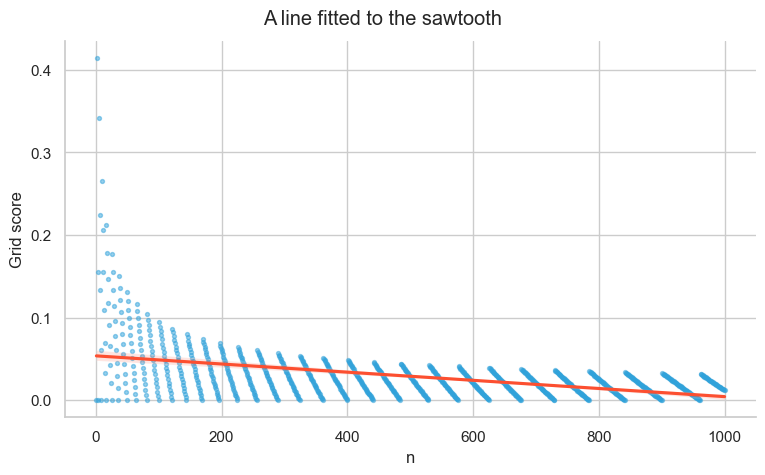

In [5]:
rho, rho_p = stats.spearmanr(grid.n, grid.score)
print(f"Spearman n vs grid score: {rho:.3f} (p={rho_p:.3e})")
X = grid[["n"]]
y = grid.score
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=7)
line = LinearRegression().fit(Xtr, ytr)
print("Hold-out R2, score ~ n:", round(r2_score(yte, line.predict(Xte)), 3))
print("Slope per extra square:", f"{line.coef_[0]:.6f}")

g = sns.lmplot(
    data=grid,
    x="n",
    y="score",
    height=4.6,
    aspect=1.7,
    scatter_kws={"s": 8, "color": PALETTE[0], "alpha": 0.5},
    line_kws={"color": PALETTE[1]},
)
g.set_axis_labels("n", "Grid score")
g.fig.suptitle("A line fitted to the sawtooth", y=1.03)
plt.show()

**Interpretation:** <br>
The rank correlation of n with the grid score is −0.414, because later puzzles pay a smaller relative charge for the same kind of empty row. A straight line still has hold-out R² 0.096. The slope is −0.000054 per extra square. The shape that matters is the reset to zero at every perfect square, which a single slope averages away.

# **6. What It Means — Working Synthesis:** <a id="Synthesis"></a> <br>
The competition ships no input table. The number it assigns to a missing puzzle is the axis-aligned grid, side ceil(sqrt(n)), scored as L / sqrt(n) − 1. Summed from n = 1 through 1000, that charge is 28.9377.

Thirty-one puzzles, the perfect squares through 961, score 0 on this grid. n = 2 is the most expensive single puzzle at 0.4142. The charge spikes again just after every later square, and each spike is smaller than the one before it. A hold-out line of score on n has R² 0.096, which is the slow decline under the sawtooth.

Any submitted packing is a set of positions and angles whose containing-square side beats this grid on the puzzles it covers. This notebook stops at the charge those packings are measured against.

**Open follow-ups:** <br>
- Record sides for small n are a published packing literature. They are a different artifact from this score surface.
- A submission file would replace the grid side with the side of a real packing, one puzzle at a time.